# Faster R-CNN: comprobación del dataset

## Objetivo

Antes de entrenar Faster R-CNN, queremos comprobar que una imagen y sus anotaciones se pueden cargar y representar en el formato que espera `torchvision`. Este notebook es una prueba de entrada de datos: **no entrena un detector, no modifica las imágenes y no cambia las particiones**.

Al terminar, deberíamos haber comprobado que:

1. Se puede emparejar cada registro del JSON COCO con su imagen.
2. La imagen se convierte a un tensor RGB `[canales, alto, ancho]`.
3. Las cajas y las etiquetas tienen las formas y tipos esperados.
4. Las cajas dibujadas coinciden visualmente con los objetos.
5. El `DataLoader` devuelve lotes de listas, sin intentar apilar imágenes de tamaños potencialmente distintos.

## Datos que usa el notebook

El script de preparación extrae las imágenes de los Parquet y genera anotaciones COCO y YOLO. Para este baseline usamos solo COCO: imágenes en `data/converted/parasites-1s07h/images/<split>/` y anotaciones en `data/converted/parasites-1s07h/annotations/instances_<split>.json`. Las particiones se llaman `train`, `val` y `test`; corresponden a los splits originales `train`, `validation` y `test`.

Las imágenes convertidas conservan el contenido original: no se redimensionan ni se les aplica aumento de datos en esta fase.

## Kernel de Jupyter

El kernel seleccionado por defecto es **VISION P5**. Es el nombre que el proyecto registra para el entorno de Python con PyTorch y las demás dependencias; no es una configuración propia de Faster R-CNN. Lo registra [`scripts/setup_env.sh`](../scripts/setup_env.sh) como `vision-p5` con el nombre visible `VISION P5`.

Si no aparece en Jupyter, activa el entorno del proyecto y vuelve a registrarlo siguiendo [las instrucciones del README](../README.md), o selecciona otro kernel que tenga instaladas las dependencias del proyecto. También puedes cambiar el kernel desde **Kernel → Change Kernel**. El nombre por defecto de este notebook se guarda en sus metadatos `kernelspec` (`display_name` y `name`); cambiar esos metadatos no instala paquetes ni crea un entorno.

## 1. Seleccionar una partición y localizar sus archivos

`SPLIT` permite inspeccionar `train`, `val` o `test`. Empezamos con `train` para depurar el cargador; la misma función servirá luego para las otras particiones. `parasite_detection.paths.DATA` resuelve la carpeta local de datos a partir de la raíz del proyecto.

In [ ]:
import json
from collections import defaultdict
from functools import partial

import matplotlib.pyplot as plt
import torch
from PIL import Image
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader
from torchvision.transforms.functional import to_tensor

from parasite_detection.paths import DATA

SPLIT = "train" # Trabajamos solo inspeccionando el conjunto de train
assert SPLIT in {"train", "val", "test"}

ANNOTATIONS_PATH = DATA / "annotations" / f"instances_{SPLIT}.json"
IMAGE_DIR = DATA / "images" / SPLIT
assert ANNOTATIONS_PATH.is_file(), f"Falta el JSON COCO: {ANNOTATIONS_PATH}"
assert IMAGE_DIR.is_dir(), f"Falta el directorio de imágenes: {IMAGE_DIR}"

print(f"Directorio de datos: {DATA}")
print(f"Partición elegida: {SPLIT}")
print(f"Anotaciones: {ANNOTATIONS_PATH}")
print(f"Imágenes: {IMAGE_DIR}")

Directorio de datos: C:\Users\RODRIGO\OneDrive - Universidade de Santiago de Compostela\UNIVERSIDAD\04_Cuarto\Visión Por Computador\Prácticas\P6\proyecto\parasite-detection-benchmark\data\converted\parasites-1s07h
Partición elegida: train
Anotaciones: C:\Users\RODRIGO\OneDrive - Universidade de Santiago de Compostela\UNIVERSIDAD\04_Cuarto\Visión Por Computador\Prácticas\P6\proyecto\parasite-detection-benchmark\data\converted\parasites-1s07h\annotations\instances_train.json
Imágenes: C:\Users\RODRIGO\OneDrive - Universidade de Santiago de Compostela\UNIVERSIDAD\04_Cuarto\Visión Por Computador\Prácticas\P6\proyecto\parasite-detection-benchmark\data\converted\parasites-1s07h\images\train


## 2. Leer el JSON COCO

COCO separa la información en listas de `images`, `annotations` y `categories`. Cada anotación apunta a una imagen mediante `image_id`; por eso agrupamos las anotaciones por ese ID. El mapa de categorías nos permitirá convertir un ID, por ejemplo `4`, en el nombre de la especie al dibujar la caja.

### ¿De dónde sale `[x, y, ancho, alto]`?

[`scripts/prepare_dataset.py`](../scripts/prepare_dataset.py) lee la caja original como `x, y, w, h` y escribe literalmente `[x, y, w, h]` en `annotations[*].bbox` del JSON COCO. Son coordenadas en píxeles, con el origen en la esquina superior izquierda.

El formato que usa torchvision para detección es `[x1, y1, x2, y2]`, donde las dos últimas coordenadas indican la esquina inferior derecha. Por eso se convierte con `x2 = x + ancho` y `y2 = y + alto`. No se normalizan las cajas.

In [2]:
def load_coco_split(split, data_dir=DATA):
    """Carga un split COCO y agrupa las anotaciones por image_id."""
    annotation_path = data_dir / "annotations" / f"instances_{split}.json"
    image_dir = data_dir / "images" / split

    with annotation_path.open(encoding="utf-8") as file:
        coco = json.load(file)

    image_records = coco["images"]
    categories = {category["id"]: category["name"] for category in coco["categories"]}
    annotations_by_image = defaultdict(list)
    for annotation in coco["annotations"]:
        annotations_by_image[annotation["image_id"]].append(annotation)

    return image_records, categories, annotations_by_image, image_dir


image_records, categories, annotations_by_image, image_dir = load_coco_split(SPLIT)
print(f"Imágenes: {len(image_records)}")
print(f"Anotaciones: {sum(map(len, annotations_by_image.values()))}")
print("Categorías COCO:", categories)

Imágenes: 1484
Anotaciones: 3667
Categorías COCO: {1: 'Ancylostoma Spp', 2: 'Ascaris Lumbricoides', 3: 'Enterobius Vermicularis', 4: 'Fasciola Hepatica', 5: 'Hymenolepis', 6: 'Schistosoma', 7: 'Taenia Sp', 8: 'Trichuris Trichiura'}


## 3. Cargar una imagen y preparar su objetivo

`load_detection_sample` carga solo la imagen solicitada, así no es necesario guardar todo el dataset en memoria. Pillow la convierte a RGB y `to_tensor` produce un tensor `float32` con forma `[C, H, W]` (Channels, height, width) y valores en `[0, 1]`.

El objetivo es un diccionario por imagen:

- `boxes`: tensor `float32` de forma `[N, 4]` con cajas `[x1, y1, x2, y2]`. Donde N es el número de elementos detectados en la imagen y cada objeto contiene una caja con 4 coordenadas.
- `labels`: tensor `int64` de forma `[N]`. COCO/torchvision usa IDs `1–8` para las especies y reserva `0` para el fondo; la categoría genérica original `parasites` no se incluye como especie.
- `image_id`: identificador COCO de la imagen.
- `area` e `iscrowd`: campos COCO que resultan útiles para evaluación.


In [3]:
def load_detection_sample(index, image_records, annotations_by_image, image_dir):
    """Devuelve una imagen RGB como tensor y su objetivo para torchvision."""
    image_info = image_records[index]
    image_id = image_info["id"]
    image_path = image_dir / image_info["file_name"]

    with Image.open(image_path) as file:
        image = to_tensor(file.convert("RGB"))

    boxes = []
    labels = []
    areas = []
    iscrowd = []
    for annotation in annotations_by_image[image_id]:
        x, y, width, height = annotation["bbox"]
        if width <= 0 or height <= 0:
            raise ValueError(f"Caja no válida en imagen {image_id}: {annotation['bbox']}")

        boxes.append([x, y, x + width, y + height])
        labels.append(annotation["category_id"])
        areas.append(annotation["area"])
        iscrowd.append(annotation["iscrowd"])

    target = {
        "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        "labels": torch.as_tensor(labels, dtype=torch.int64),
        "image_id": torch.tensor([image_id], dtype=torch.int64),
        "area": torch.as_tensor(areas, dtype=torch.float32),
        "iscrowd": torch.as_tensor(iscrowd, dtype=torch.int64),
    }
    return image, target


sample_image, sample_target = load_detection_sample(
    0, image_records, annotations_by_image, image_dir
)
print("Forma/tipo de imagen:", tuple(sample_image.shape), sample_image.dtype)
print("Forma/tipo de cajas:", tuple(sample_target["boxes"].shape), sample_target["boxes"].dtype)
print("Forma/tipo de etiquetas:", tuple(sample_target["labels"].shape), sample_target["labels"].dtype)

Forma/tipo de imagen: (3, 640, 640) torch.float32
Forma/tipo de cajas: (1, 4) torch.float32
Forma/tipo de etiquetas: (1,) torch.int64


**Forma/tipo de imagen: (3, 640, 640) torch.float32** Una imagen de 640*640 píxeles y 3 canales RGB 

**Cajas (1, 4)** Tenemos un objeto anotado/registrado con 4 coordenadas, que son las 4 coordenadas de la bounding box

**Etiquetas (1,)** La caja tiene una etiqueta que la identifica

## 4. Comprobar tensores y etiquetas

Las siguientes aserciones son las comprobaciones mencionadas en el objetivo. Si una condición no se cumple, la celda se detiene con `AssertionError`; si todas pasan, imprime el mensaje final. En particular, se comprueba que la imagen tiene tres canales, que los píxeles son finitos y están en `[0, 1]`, que cada caja tiene cuatro coordenadas, y que las etiquetas pertenecen a los ocho IDs de especie.

In [8]:
assert sample_image.ndim == 3 and sample_image.shape[0] == 3, "Se esperaba una imagen [3, H, W]"  # Comprueba que sea una imagen RGB con forma [3, H, W].
assert sample_image.dtype == torch.float32  # Comprueba que los valores de la imagen sean float32.
assert torch.isfinite(sample_image).all()  # Comprueba que no haya valores NaN ni infinitos.
assert sample_image.min() >= 0 and sample_image.max() <= 1  # Comprueba que los valores de píxel estén entre 0 y 1.

boxes = sample_target["boxes"]  # Guarda el tensor de cajas para las comprobaciones.
labels = sample_target["labels"]  # Guarda el tensor de etiquetas para las comprobaciones.
assert boxes.ndim == 2 and boxes.shape[1] == 4, "Las cajas deben tener forma [N, 4]"  # Comprueba que cada caja tenga cuatro coordenadas.
assert boxes.shape[0] == labels.shape[0], "Debe haber una etiqueta por caja"  # Comprueba que haya una etiqueta por cada caja.
assert boxes.dtype == torch.float32  # Comprueba que las coordenadas sean float32.
assert labels.dtype == torch.int64  # Comprueba que las etiquetas sean enteros int64.
assert ((labels >= 1) & (labels <= 8)).all(), "Hay etiquetas fuera de los IDs de especie 1–8"  # Comprueba que los IDs de especie estén entre 1 y 8.
assert (boxes[:, 2] > boxes[:, 0]).all() and (boxes[:, 3] > boxes[:, 1]).all()  # Comprueba que todas las cajas tengan ancho y alto positivos.
print("Imagen, cajas y etiquetas: comprobaciones correctas")  # Confirma que todas las comprobaciones han pasado.

Imagen, cajas y etiquetas: comprobaciones correctas


## 5. Visualizar las cajas

Dibujamos las coordenadas ya convertidas a `[x1, y1, x2, y2]`. Este paso sirve para detectar errores que las comprobaciones de forma no detectan, como cajas desplazadas o una conversión de coordenadas incorrecta. El título indica el ID COCO y el número de objetos.

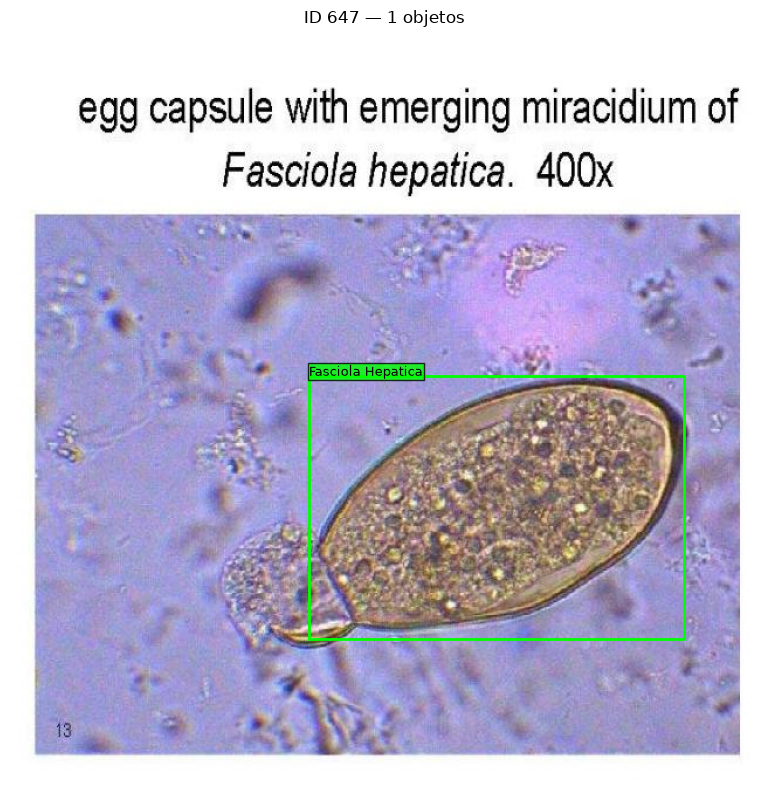

In [5]:
def draw_sample(image, target, categories, ax):
    """Dibuja una imagen y sus cajas sobre el eje de Matplotlib recibido."""
    ax.imshow(image.permute(1, 2, 0))
    for box, label in zip(target["boxes"], target["labels"]):
        x1, y1, x2, y2 = box.tolist()
        class_name = categories[int(label)]
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="lime", linewidth=2,
        ))
        ax.text(x1, y1, class_name, color="black", fontsize=9,
                bbox={"facecolor": "lime", "alpha": 0.8, "pad": 1})

    image_id = target["image_id"].item()
    ax.set_title(f"ID {image_id} — {len(target['labels'])} objetos")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(8, 8))
draw_sample(sample_image, sample_target, categories, ax)
plt.tight_layout()

## 6. Probar un batch con `DataLoader`

En detección, las imágenes de un batch no siempre tienen las mismas dimensiones y cada una puede tener un número distinto de cajas. El `collate_fn` de abajo carga las muestras pedidas y las devuelve como dos tuplas: una de imágenes y otra de objetivos. Así no se intenta apilar todo en un único tensor rectangular.

Para evitar una clase propia, usamos `range(len(image_records))` como fuente ligera de índices y hacemos la carga en una función normal. `batch_size=2` solo sirve para esta prueba; `num_workers=0` mantiene sencillo el uso desde Jupyter, especialmente en Windows.

In [10]:
def collate_detection_batch(indices, image_records, annotations_by_image, image_dir):
    """Carga los índices del batch y mantiene imágenes/objetivos como tuplas."""
    samples = [
        load_detection_sample(index, image_records, annotations_by_image, image_dir)
        for index in indices
    ]
    return tuple(zip(*samples))

# cargamos cada imagen y sus anotaciones para luego devolver cada una por separado
collate_fn = partial(
    collate_detection_batch,
    image_records=image_records,
    annotations_by_image=annotations_by_image,
    image_dir=image_dir,
)
train_loader = DataLoader(
    range(len(image_records)),
    batch_size=4,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
)

images, targets = next(iter(train_loader))
assert len(images) == len(targets) == 4
for image, target in zip(images, targets):
    assert image.ndim == 3 and image.shape[0] == 3
    assert target["boxes"].shape == (len(target["labels"]), 4)

print(f"Batch correcto: {len(images)} imágenes")
print("Formas de imagen:", [tuple(image.shape) for image in images])
print("Número de cajas por imagen:", [len(target["boxes"]) for target in targets])

Batch correcto: 4 imágenes
Formas de imagen: [(3, 640, 640), (3, 640, 640), (3, 640, 640), (3, 640, 640)]
Número de cajas por imagen: [2, 2, 1, 1]


También dibujamos el batch completo. Si las imágenes tuviesen tamaños distintos, Matplotlib las mostraría en ejes separados; el `DataLoader` no necesita convertirlas a un tamaño común.

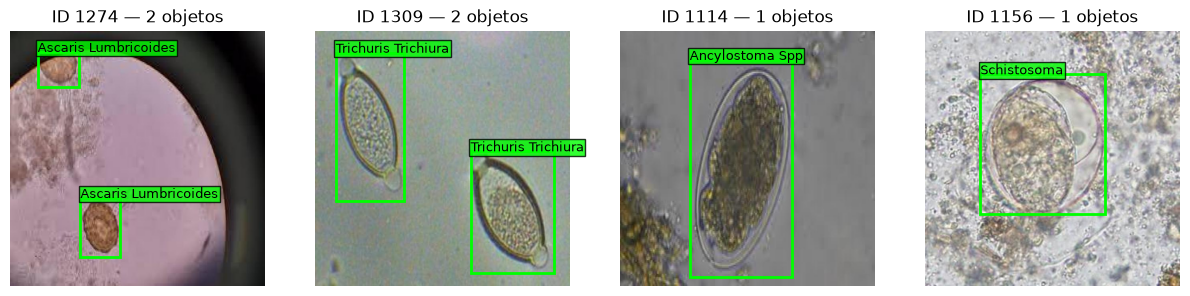

In [11]:
fig, axes = plt.subplots(1, len(images), figsize=(12, 6), squeeze=False)
for ax, image, target in zip(axes[0], images, targets):
    draw_sample(image, target, categories, ax)
plt.tight_layout()

## Resultado y siguiente paso

Si todas las celdas terminan sin errores y las cajas se ven alineadas con los parásitos, la ruta de lectura COCO y el formato de batch están listos para una prueba de entrenamiento. En el siguiente paso se puede reutilizar `load_coco_split`, `load_detection_sample` y `collate_detection_batch` en el entrenamiento; cuando el flujo esté validado en el notebook, se podrán mover esas funciones a `src/parasite_detection/`.